In [1]:
from pathlib import Path
import os 

import pandas as pd
import numpy as np
import scanpy as sc 
import matplotlib.pyplot as plt 
import seaborn as sns 
from matplotlib.patches import Patch

from dotenv import dotenv_values

In [ ]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Ext_Fig_04" 
os.makedirs(OUTDIR, exist_ok=True)

OBJECTS_DIR = DATADIR / "9_objects"
SC_ADATA_FP = OBJECTS_DIR / "singlecell" / "hypomap3d_singlecell_control.h5ad" 

In [ ]:
adata = sc.read_h5ad(SC_ADATA_FP, backed="r")
agrp = adata[adata.obs.L2_descr.str.contains("TU-ARH Otp.Six6"),:].to_memory()

In [ ]:
sc.pp.normalize_total(agrp, target_sum=10_000)
sc.pp.log1p(agrp)

# UMAP

## Full 

In [5]:
def plot_and_save_GE_ctrl_only(adata, genes_to_plot_list, plot_save_dir, save_string_suffix=None, scattersize=15, vmax=None):

    for gene in genes_to_plot_list:

        # Create high-resolution figure and axis
        fig, ax = plt.subplots(figsize=(10, 10)) 

        # Plot with Scanpy onto the given axis
        sc.pl.umap(
            adata[adata.obs.IsControl], 
            color=gene,
            ax=ax,
            show=False,
            size=scattersize,
            vmax=vmax
        )

        # --- Rasterize the scatter plot points ---
        for artist in ax.collections:
            artist.set_rasterized(True)

        # Remove default title, borders, ticks, and labels
        ax.set_title(gene, fontsize=30, fontweight="bold")
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_aspect('equal')

        # Modify the colorbar
        for cax in fig.axes:
            if cax != ax:
                # Shrink the colorbar by modifying its position
                pos = cax.get_position()
                cax.set_position([
                    pos.x0 + 0,      # move right
                    pos.y0 + 0,       # move up
                    pos.width * 20,     # stretch horizontally
                    pos.height * 1#0.75  # shrink vertically
                ])

                # Set label and tick styles
                cax.set_ylabel("log1p(CP10K)", fontsize=30, fontweight='bold', labelpad=10)
                cax.tick_params(labelsize=30)
                for label in cax.get_yticklabels():
                    label.set_fontweight('bold')
                break



        # Save figure
        save_name = f"umap_{gene}_expr_C_only"
        if isinstance(save_string_suffix, str):
            save_name += save_string_suffix

        fig.savefig(
            Path(plot_save_dir) / f"{save_name}.pdf",
            dpi=500,
            format="pdf",
            bbox_inches="tight"
        )


## TU-ARH Otp.Six6 subclasses 

In [28]:
agrp = agrp[(agrp.obsm["X_umap"][:, 0] > 8) & (agrp.obsm["X_umap"][:, 1] < -11)]

In [32]:
#plt.hist(agrp.obsm["X_umap"][:, 0], bins=100)

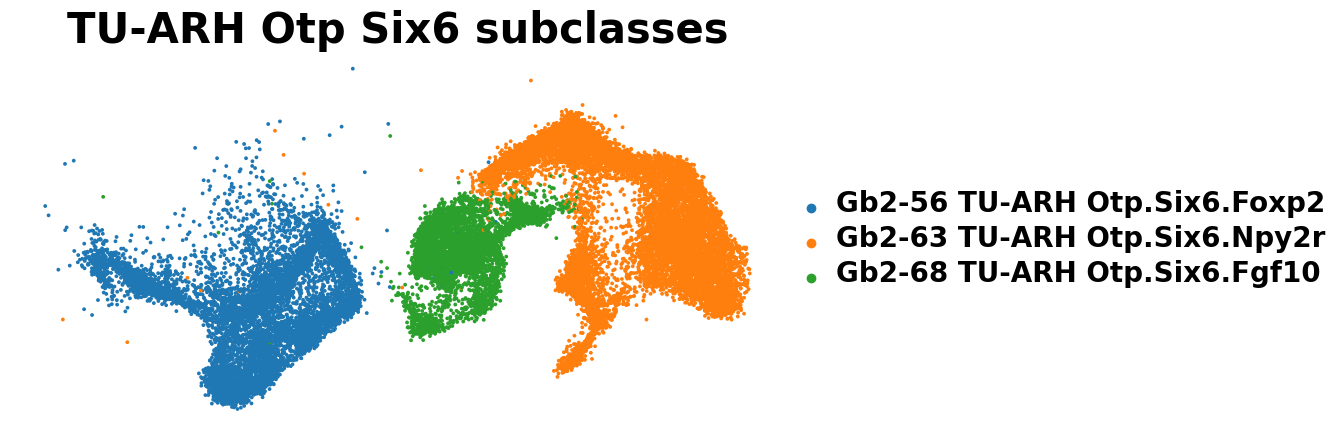

In [ ]:

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(10, 10), ) 

# Pass the axis to Scanpy
sc.pl.umap(agrp, color="L2_descr", ax=ax, s=30, show=False,  )

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("TU-ARH Otp Six6 subclasses", fontweight="bold", fontsize=30)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')


# --- Customize legend ---
leg = ax.get_legend()
if leg is not None:
    # Change font size and weight
    for text in leg.get_texts():
        text.set_fontsize(20)
        text.set_fontweight("bold")

fig.canvas.draw()

plt.savefig(OUTDIR / "umap_L2_tu_arh_otp_six6_control.pdf", format="pdf", dpi=300, bbox_inches="tight") 

In [34]:
genes_to_plot_list = ["Foxp2", "Npy2r", "Fgf10"]
save_string_suffix = "_agrp_l2"
subclass_max = np.max(adata[:, genes_to_plot_list].X.toarray())
subclass_max

np.float32(7.4373026)

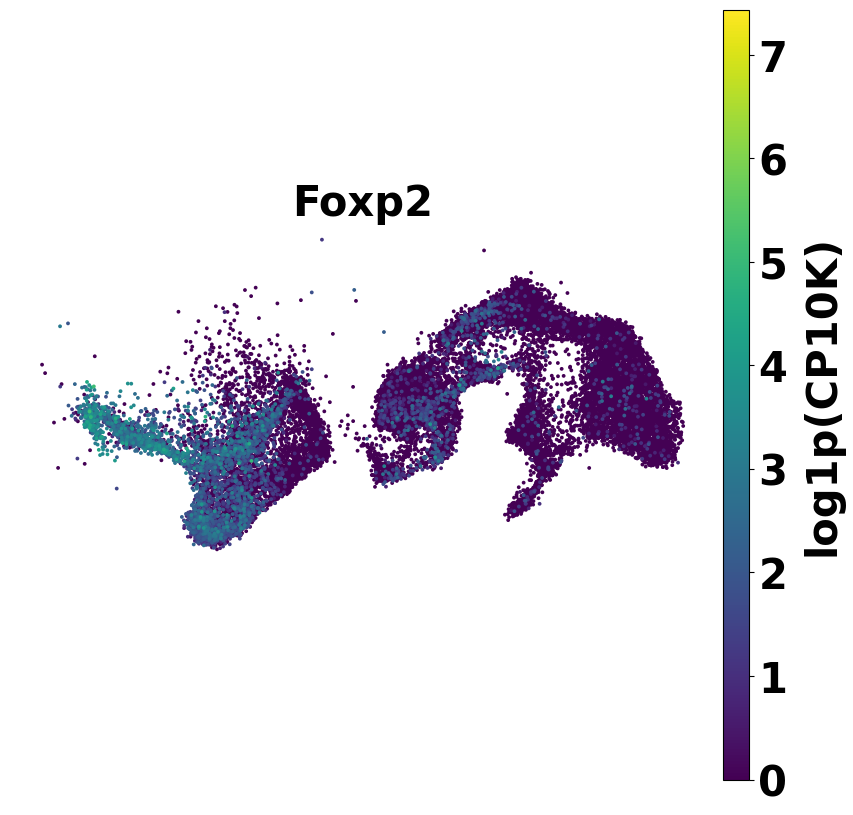

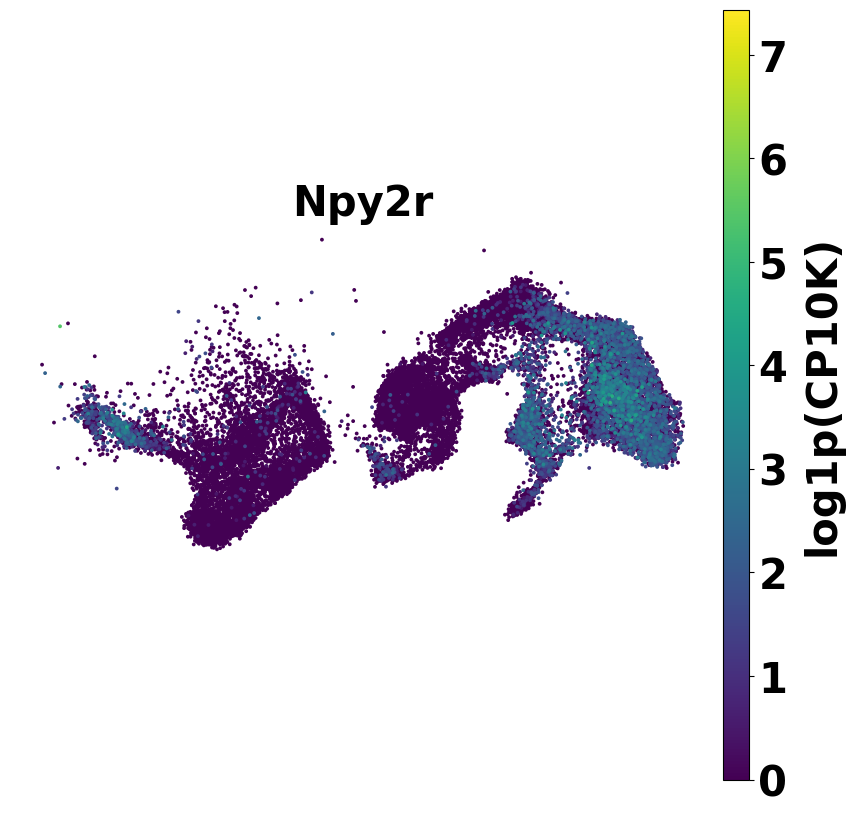

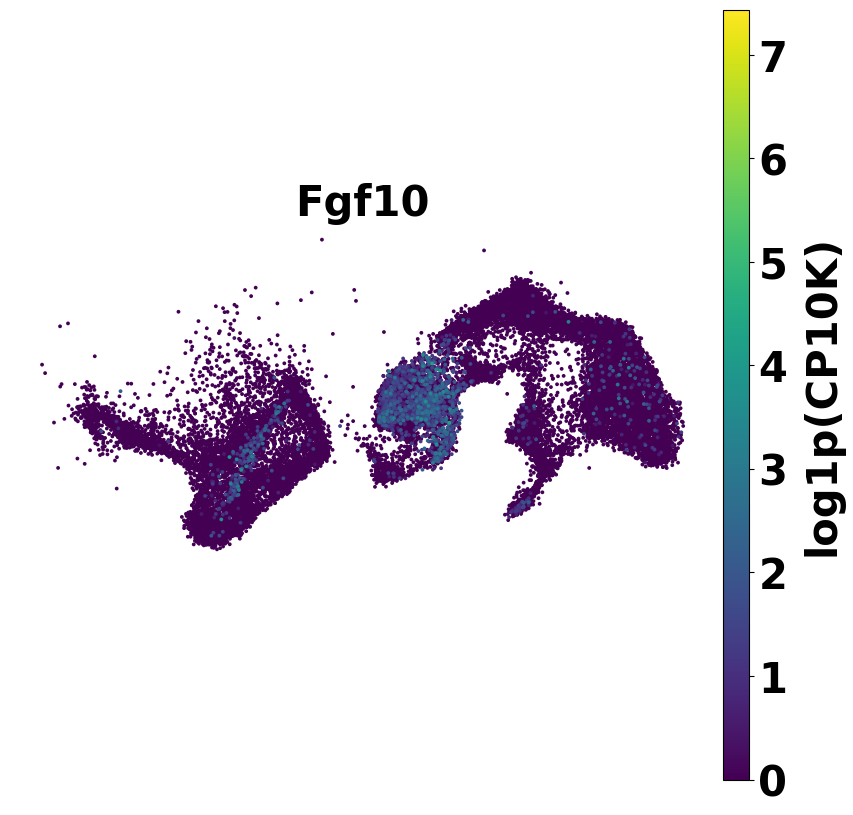

In [ ]:
plot_and_save_GE_ctrl_only(agrp, genes_to_plot_list, plot_save_dir = OUTDIR, 
    save_string_suffix=save_string_suffix,scattersize=30,
    vmax=subclass_max)

# Dotplot

In [41]:
agrp_markers_list = ["Otp", "Six6", 

    "Sst", "Agrp", "Npy", "Npy2r", "Tbx3", "Lepr",  "Ghsr", 

    "Foxp2", "Prkcq", "Htr2c", "Prlr", "Six3", "Bcl11a", "Bcl11b", 

    "Tacr1", "Calcrl", "Pthlh", "Abi3bp", "Pth2r",  "Fgf10", ]


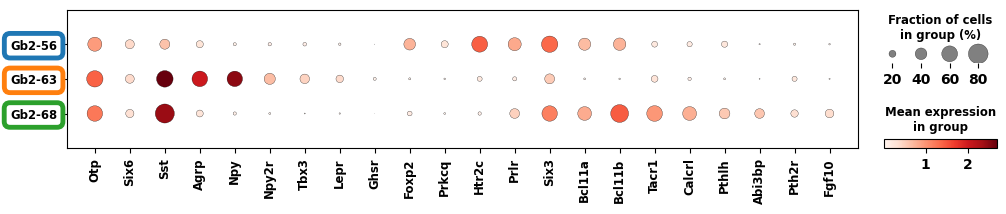

In [45]:
# Compute total height based on number of genes
total_height = 0.6 * len(agrp.obs.L2_ID.unique())

# Create DotPlot object with custom height
dotplot_obj = sc.pl.DotPlot(
    agrp,
    var_names=agrp_markers_list,
    groupby="L2_ID",
    figsize=(12, total_height),  # (width, height)
    cmap='Reds' ,
)
# Create the figure
dotplot_obj.make_figure()

# Access the y-axis
ax = dotplot_obj.ax_dict['mainplot_ax']

# Modify the y-tick labels 
for i, label in enumerate(ax.get_yticklabels()):
    text = label.get_text()
    color = agrp.uns["L2_descr_colors"][i]
    label.set_bbox(dict(facecolor="white", edgecolor=color, boxstyle='round,pad=0.5',
        linewidth = 3.5))

for label in ax.get_xticklabels():
    label.set_fontweight('bold')
for label in ax.get_yticklabels():
    label.set_fontweight('bold')

cbar_ax = dotplot_obj.fig.axes[-1]
for txt_obj in cbar_ax.texts + cbar_ax.get_yticklabels() + cbar_ax.get_xticklabels():
    txt_obj.set_fontweight('bold')
    txt_obj.set_fontsize(10)

label = cbar_ax.get_ylabel()
if label:
    cbar_ax.set_ylabel(label, fontweight='bold')

label = cbar_ax.get_xlabel()
if label:
    cbar_ax.set_xlabel(label, fontweight='bold')

for text in cbar_ax.texts:
    text.set_fontweight('bold')

for text in dotplot_obj.ax_dict['size_legend_ax'].texts:
    text.set_fontweight('bold')
    

size_legend_ax = dotplot_obj.ax_dict['size_legend_ax']

# Try both x and y tick labels (only one will apply)
for tick in size_legend_ax.get_xticklabels() + size_legend_ax.get_yticklabels():
    tick.set_fontweight('bold')

# Make all text in the figure bold
for text_obj in dotplot_obj.fig.findobj(match=plt.Text):
    if "expression" in text_obj.get_text().lower() or "fraction" in text_obj.get_text().lower():
        text_obj.set_fontweight('bold')
    if text_obj.get_text().lower() in ["20", "40", "60", "80", "100"]:
        text_obj.set_fontsize(10)

size_ax = dotplot_obj.ax_dict["size_legend_ax"]

pos = size_ax.get_position()
size_ax.set_position([
    pos.x0,
    pos.y0 + 0.15,   
    pos.width,
    pos.height
])

plt.savefig(OUTDIR / "dotplot_L2_agrp_marker.pdf", format="pdf", bbox_inches="tight")

plt.show()
